# How Hot Did Berlin's Rail Corridors Get? Measuring Peak Surface Temperature at 30 m

In late June 2026, Germany broke its all-time temperature record twice in one week, peaking at
41.8 °C on June 27. Sections of the A2 motorway buckled, and Deutsche Bahn asked passengers to
postpone non-essential travel, citing heat stress on tracks, signals, and overhead lines.

This notebook measures how hot Berlin's surface rail network actually got during that heatwave —
regional and mainline rail, S-Bahn/light rail, and trams; not the U-Bahn, which is out of scope for a
surface-temperature question — using Landsat 8/9 thermal imagery at 30 m resolution.

Two methodological choices follow directly from the question "how hot did it get", not "what was the
average nearby temperature":

1. **Take the maximum, not the mean**, of every Landsat scene in the heatwave window. Characterising
   an extreme means capturing its peak, not diluting it into an average.
2. **Sample the 30 m grid with a buffer + zonal max/mean per ~1 km segment**, not a nearest-neighbour
   point every kilometre. The corridor is a linear feature much narrower than 1 km; a single point per
   km reads only a small fraction of the available pixels, and can just as easily land on a rooftop or
   the tree line next to the tracks as on the corridor itself.

The notebook builds both a naive point sample and the buffer + zonal estimate, so the effect of the
second choice is visible directly, not just asserted.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.ops import substring
import xarray as xr
import matplotlib.pyplot as plt

import pystac_client
import planetary_computer
from odc.stac import load as odc_load
from rasterio.features import rasterize

PHI = 1.618  # golden ratio for figure proportions

DATA_DIR = Path("../00_data")
RESULTS_DIR = Path("../02_results")
PLOTS_DIR = RESULTS_DIR / "plots"
for d in (DATA_DIR, RESULTS_DIR, PLOTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- Analysis parameters -----------------------------------------------------
AOI_NAME = "berlin"
GEOFABRIK_URL = "https://download.geofabrik.de/europe/germany/berlin-latest-free.gpkg.zip"

EPSG_ANALYSIS = 3035        # ETRS89-LAEA: equal-area, metric
SEGMENT_SPACING_M = 1000    # ~1 km line segments, for both the point sample and the zonal buffer
CORRIDOR_BUFFER_M = 15      # half-width of the zonal buffer -> 30 m corridor, matching the Landsat grid

# The heatwave window brackets the Jun 27 record.
HEATWAVE_WINDOW = ("2026-06-18", "2026-07-03")

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

## Step 1 — The railway network, without the Overpass wait

The natural instinct is to query OpenStreetMap live with `osmnx` or the Overpass API. For a small area
that works well. For a region or a country it does not: a `railway=rail` query at that scale returns
tens of thousands of ways, and Overpass either throttles or times out.

Geofabrik solves this. It publishes daily-updated OSM extracts per country and sub-region, including a
ready-made GeoPackage with a railways layer. The cell below caches the download, so you only pay the
cost once. (For all of Germany, swap the URL for the country extract and budget ~2.5 GB.)

In [2]:
import urllib.request
import zipfile

zip_path = DATA_DIR / f"{AOI_NAME}-free.gpkg.zip"
gpkg_candidates = list(DATA_DIR.glob("*.gpkg"))

if not gpkg_candidates:
    if not zip_path.exists():
        print("Downloading Geofabrik extract...")
        urllib.request.urlretrieve(GEOFABRIK_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR, members=[n for n in z.namelist() if n.endswith(".gpkg")])
    gpkg_candidates = list(DATA_DIR.glob("*.gpkg"))

gpkg_path = gpkg_candidates[0]
print("Using:", gpkg_path.name)

Using: berlin.gpkg


The layer mixes everything OSM tags as railway: `rail` (mainline and regional heavy rail — this is
also where Geofabrik's simplified schema puts most of the S-Bahn), `light_rail` (the rest of the
S-Bahn and other light-rail lines), `tram` (Straßenbahn), `subway` (U-Bahn), plus a handful of
`narrow_gauge`/`miniature_railway` features. All of them, except the U-Bahn, run exposed to the sun for
most of their length, so all of them are relevant to surface heat: we keep
`fclass in ("rail", "light_rail", "tram")` and drop tunnels (`tunnel == "F"`). The U-Bahn is excluded
outright, not just where tunnelled — in the Berlin extract, about a quarter of its length sits on
`tunnel == "F"` (viaduct sections), but "metro" is out of scope regardless of whether a given stretch
happens to be elevated. We then reproject to ETRS89-LAEA (EPSG:3035), the standard equal-area CRS for
Europe, so lengths and sampling distances are in honest metres.

In [3]:
railways = gpd.read_file(gpkg_path, layer="gis_osm_railways_free")
print(railways["fclass"].value_counts())

SURFACE_FCLASSES = ("rail", "light_rail", "tram")  # regional/heavy rail, S-Bahn/VLT, trams — no subway
rail = railways[railways["fclass"].isin(SURFACE_FCLASSES) & (railways["tunnel"] == "F")].copy()

# WGS84 bounds (+ ~2 km buffer) drive the satellite query later
AOI_BBOX = tuple(np.array(rail.total_bounds) + np.array([-0.03, -0.02, 0.03, 0.02]))

rail = rail.to_crs(EPSG_ANALYSIS)
network_km = rail.geometry.length.sum() / 1000
print(f"\nSurface rail+light_rail+tram features: {len(rail):,}")
print(rail["fclass"].value_counts())
print(f"Network length analysed: {network_km:,.0f} km")
print(f"AOI bbox (WGS84): {np.round(AOI_BBOX, 3)}")

fclass
rail                 4318
light_rail           3051
tram                 2300
subway               1215
narrow_gauge           47
miniature_railway      37
Name: count, dtype: int64

Surface rail+light_rail+tram features: 9,220
fclass
rail          4101
light_rail    2886
tram          2233
Name: count, dtype: int64
Network length analysed: 2,026 km
AOI bbox (WGS84): [12.95  52.34  13.792 52.692]


## Step 2 — Two ways to reach the line: points and segments

Two representations of the same network, built once and reused throughout:

- **Sample points**, one per ~1 km of track (vectorised `shapely.line_interpolate_point`). These give
  the naive nearest-neighbour baseline: what a typical point-sampling workflow would report.
- **Line segments**, the same ~1 km spacing, each buffered to a 30 m-wide strip (roughly one Landsat
  pixel width — a sampling choice to reliably catch pixels immediately along the line, not a claim
  about the physical width of the right-of-way). These support the zonal statistics below.

Looping over thousands of OSM ways with `.interpolate()` is slow; `shapely` exposes vectorised
alternatives for the point case. The segment case still needs a per-line cut (`shapely.ops.substring`
has no vectorised form), but at Berlin's scale that is a matter of seconds, not minutes.

In [4]:
lengths = rail.geometry.length.values
n_samples = np.maximum(np.round(lengths / SEGMENT_SPACING_M).astype(int), 1)

rep_geoms = np.repeat(rail.geometry.values, n_samples)
fractions = np.concatenate([(np.arange(n) + 0.5) / n for n in n_samples])
points = shapely.line_interpolate_point(rep_geoms, fractions, normalized=True)

samples = gpd.GeoDataFrame(
    {
        "osm_id": np.repeat(rail["osm_id"].values, n_samples),
        "name": np.repeat(rail["name"].values, n_samples),
        "rep_km": np.repeat(lengths / n_samples / 1000, n_samples),
    },
    geometry=points,
    crs=rail.crs,
)
print(f"{len(samples):,} sample points representing {samples['rep_km'].sum():,.0f} km of track")

9,418 sample points representing 2,026 km of track


In [5]:
def cut_into_segments(lines_gdf, spacing_m):
    """~1 km line segments per rail line (last segment absorbs any remainder)."""
    records = []
    for geom, length, osm_id, name in zip(
        lines_gdf.geometry.values, lines_gdf.geometry.length.values,
        lines_gdf["osm_id"].values, lines_gdf["name"].values,
    ):
        n = max(round(length / spacing_m), 1)
        seg_len = length / n
        for i in range(n):
            piece = substring(geom, i * seg_len, (i + 1) * seg_len)
            records.append({"osm_id": osm_id, "name": name, "seg_km": seg_len / 1000, "geometry": piece})
    return gpd.GeoDataFrame(records, crs=lines_gdf.crs)

segments = cut_into_segments(rail, SEGMENT_SPACING_M)
segments["geometry"] = segments.geometry.buffer(CORRIDOR_BUFFER_M)
print(f"{len(segments):,} segments of ~{SEGMENT_SPACING_M/1000:.0f} km, "
      f"buffered to a {2*CORRIDOR_BUFFER_M:.0f} m corridor width, "
      f"{segments['seg_km'].sum():,.0f} km of track total")

9,418 segments of ~1 km, buffered to a 30 m corridor width, 2,026 km of track total


## Step 3 — Landsat 8/9 surface temperature, no account required

Landsat 8/9 Collection 2 Level-2 ships a surface temperature product (`lwir11`, ST_B10: 100 m native,
distributed on a 30 m grid) in the Planetary Computer catalog, same STAC access pattern as everything
else here, no account. Overpass is ~10:00 local, so this is a mid-morning view — the gain over a 1 km
sensor is spatial, not temporal: rail corridors (dark ballast, steel, no shade) stand out several
degrees above their surroundings, which is exactly what a coarser pixel averages away.

We take every low-cloud scene in the heatwave window and keep, per pixel, the maximum across scenes.

In [6]:
search = catalog.search(
    collections=["landsat-c2-l2"], bbox=AOI_BBOX,
    datetime=f"{HEATWAVE_WINDOW[0]}/{HEATWAVE_WINDOW[1]}",
    query={"eo:cloud_cover": {"lt": 40}, "platform": {"in": ["landsat-8", "landsat-9"]}},
)
ls_items = list(search.item_collection())
for it in ls_items:
    print(it.id, "| cloud:", round(it.properties["eo:cloud_cover"], 1), "%")

ds_ls = odc_load(ls_items, bands=["lwir11"], crs=f"EPSG:{EPSG_ANALYSIS}",
                 resolution=30, bbox=AOI_BBOX, groupby="solar_day")
LANDSAT_GEOBOX = ds_ls.odc.geobox  # captured now, reused for zonal stats below
st = ds_ls["lwir11"].where(ds_ls["lwir11"] > 0) * 0.00341802 + 149.0 - 273.15
lst_landsat = st.max(dim="time", skipna=True).compute()
print(f"\nLandsat ST over AOI: max {float(lst_landsat.max()):.1f} deg C, "
      f"p95 {float(lst_landsat.quantile(0.95)):.1f} deg C")

LC09_L2SP_192024_20260628_02_T1 | cloud: 26.1 %
LC08_L2SP_193023_20260627_02_T1 | cloud: 5.4 %
LC09_L2SP_193024_20260619_02_T1 | cloud: 26.0 %

Landsat ST over AOI: max 74.4 deg C, p95 45.3 deg C


A note on interpretation: cloud contamination can survive the `eo:cloud_cover` filter, which is a
scene-level average, not a per-pixel mask. For a final version of the maps below, spot-check the scene
list above and consider masking with `qa_pixel` if any scene looks suspect.

## Step 4 — Point sample vs. buffer + zonal max

Reading a 30 m grid with points spaced 1 km apart wastes most of what the sensor offers: only 1 of
every ~33 Landsat pixels along the corridor is ever read, and nearest-neighbour can land on ballast, a
platform roof, or the tree line next to the track with equal probability.

The fix matches the sampling geometry to the sensor: for each buffered segment, take the zonal
**max** and **mean** of every pixel that touches it. Each segment now speaks for ~33 pixels along its
length instead of one.

In [7]:
def sample_raster(da, gdf):
    xs = xr.DataArray(gdf.geometry.x.values, dims="points")
    ys = xr.DataArray(gdf.geometry.y.values, dims="points")
    return da.sel(x=xs, y=ys, method="nearest").values

samples["lst_landsat"] = sample_raster(lst_landsat, samples)
print(samples["lst_landsat"].describe().round(1))

count    9405.0
mean       36.2
std         8.0
min         0.8
25%        30.4
50%        36.3
75%        42.3
max        57.0
Name: lst_landsat, dtype: float64


In [8]:
def zonal_stats_along_line(segments_gdf, da, geobox, prefix):
    """Max/mean/pixel count per segment, from every pixel touching its buffer."""
    shapes = list(zip(segments_gdf.geometry.values, range(1, len(segments_gdf) + 1)))
    seg_ids = rasterize(
        shapes, out_shape=geobox.shape, transform=geobox.affine,
        fill=0, all_touched=True, dtype="int32",
    )
    vals = da.values
    mask = (seg_ids > 0) & ~np.isnan(vals)
    stats = pd.DataFrame({"segment_id": seg_ids[mask], "value": vals[mask]})
    zonal = stats.groupby("segment_id")["value"].agg(["max", "mean", "count"])
    zonal.columns = [f"{prefix}_zonal_max", f"{prefix}_zonal_mean", f"{prefix}_n_pixels"]
    zonal.index = zonal.index - 1  # back to segments_gdf's 0-based positional index
    return segments_gdf.join(zonal, how="left")

segments = zonal_stats_along_line(segments, lst_landsat, LANDSAT_GEOBOX, prefix="lst_landsat")
covered = segments["lst_landsat_n_pixels"].notna().mean()
print(f"{covered:.1%} of segments intersect at least one valid Landsat pixel")
print(segments[["lst_landsat_zonal_max", "lst_landsat_zonal_mean", "lst_landsat_n_pixels"]]
      .describe().round(1))

point_p95 = np.nanpercentile(samples["lst_landsat"], 95)
zonal_p95 = np.nanpercentile(segments["lst_landsat_zonal_max"].dropna(), 95)
print(f"\nPoint sampling (1 km spacing, nearest 30 m pixel):        p95 = {point_p95:.1f} deg C")
print(f"Buffer + zonal max (1 km segment, 30 m corridor, all pixels): p95 = {zonal_p95:.1f} deg C")
print(f"Difference: {zonal_p95 - point_p95:+.1f} deg C — pixels the point sampling never touched")

52.4% of segments intersect at least one valid Landsat pixel
       lst_landsat_zonal_max  lst_landsat_zonal_mean  lst_landsat_n_pixels
count                 4938.0                  4938.0                4938.0
mean                    37.1                    36.1                  11.1
std                      7.9                     7.7                  16.3
min                      7.5                     2.1                   1.0
25%                     31.7                    30.9                   2.0
50%                     37.4                    36.3                   5.0
75%                     43.0                    41.7                  12.0
max                     59.1                    58.3                 115.0

Point sampling (1 km spacing, nearest 30 m pixel):        p95 = 48.2 deg C
Buffer + zonal max (1 km segment, 30 m corridor, all pixels): p95 = 48.8 deg C
Difference: +0.6 deg C — pixels the point sampling never touched


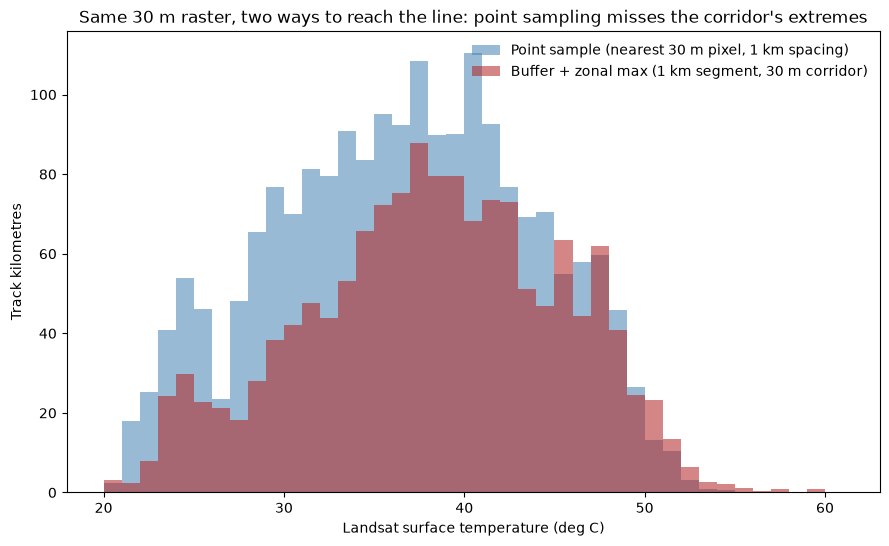

In [9]:
fig, ax = plt.subplots(figsize=(9, 9 / PHI))
bins = np.arange(20, 62, 1)

m_pt = samples["lst_landsat"].notna()
ax.hist(samples.loc[m_pt, "lst_landsat"], bins=bins, weights=samples.loc[m_pt, "rep_km"],
        alpha=0.55, label="Point sample (nearest 30 m pixel, 1 km spacing)", color="steelblue")

m_zonal = segments["lst_landsat_zonal_max"].notna()
ax.hist(segments.loc[m_zonal, "lst_landsat_zonal_max"], bins=bins,
        weights=segments.loc[m_zonal, "seg_km"],
        alpha=0.55, label="Buffer + zonal max (1 km segment, 30 m corridor)", color="firebrick")

ax.set_xlabel("Landsat surface temperature (deg C)")
ax.set_ylabel("Track kilometres")
ax.set_title("Same 30 m raster, two ways to reach the line: point sampling misses the corridor's extremes")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "hist_landsat_point_vs_zonal.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 5 — How much of the network ran hot, and where

All statistics from here use the buffer + zonal max per segment — the estimator that actually reads
the corridor — weighted by the track-kilometres each segment represents.

In [10]:
def weighted_mean(values, weights):
    return float(np.average(values, weights=weights))

def km_share(mask, weights):
    return float(weights[mask].sum()), float(weights[mask].sum() / weights.sum())

valid = segments.dropna(subset=["lst_landsat_zonal_max"]).copy()
w = valid["seg_km"].values

summary = {
    "network_km_analysed": float(valid["seg_km"].sum()),
    "mean_zonal_max": weighted_mean(valid["lst_landsat_zonal_max"], w),
    "max_zonal_max": float(valid["lst_landsat_zonal_max"].max()),
    "mean_zonal_mean": weighted_mean(valid["lst_landsat_zonal_mean"], w),
}
for threshold in (40, 45, 50):
    km, share = km_share(valid["lst_landsat_zonal_max"].values >= threshold, w)
    summary[f"km_ge_{threshold}C"] = km
    summary[f"share_ge_{threshold}C"] = share

summary_df = pd.Series(summary).round(3).rename("value").to_frame()
summary_df

,value
network_km_analysed,1476.111
mean_zonal_max,37.766
max_zonal_max,59.087
mean_zonal_mean,36.031
km_ge_40C,598.666
share_ge_40C,0.406
km_ge_45C,286.112
share_ge_45C,0.194
km_ge_50C,50.950
share_ge_50C,0.035


In [11]:
named = valid.dropna(subset=["name"]).copy()
named = named[named["name"].str.strip().str.len() > 0]  # OSM: unnamed ways come as "" in the GPKG
named["w_max"] = named["lst_landsat_zonal_max"] * named["seg_km"]

corridors = named.groupby("name").agg(km=("seg_km", "sum"), w_max=("w_max", "sum"))
corridors["mean_zonal_max"] = corridors["w_max"] / corridors["km"]
corridors = (
    corridors[corridors["km"] >= 5]
    .sort_values("mean_zonal_max", ascending=False)
    .drop(columns=["w_max"])
    .round(2)
)
corridors.head(10)

,km,mean_zonal_max
name,,
Berlin-Hamburger Bahn,9.71,48.95
Dresdner Bahn,20.35,47.02
Neukölln-Mittenwalder Eisenbahn,5.63,45.35
Schnellfahrstrecke Oebisfelde–Spandau,27.47,44.48
Anhalter Bahn,14.31,42.80
Bahnstrecke Berlin–Görlitz,9.21,39.82
Niederschlesisch-Märkische Eisenbahn,14.30,38.59
Berliner Außenring,60.94,38.34
Bötzowbahn,5.06,37.19


## Step 6 — From surface temperature to rail steel: an envelope, not a map

No satellite measures rail temperature. The honest chain is: Landsat gives the **spatial pattern** of
thermal load along the corridor; the **magnitude** anchor comes from air temperature and rail
engineering. The standard rule used by infrastructure managers (Network Rail, among others) is that
rail in direct sun runs up to ~20 °C above air temperature; Deutsche Bahn's own communications cite
rail temperatures up to ~75 °C in extreme cases. So the estimate is an envelope conditional on
exposure:

`T_rail(max) ~ T_air(max) + 10 to 20 °C` for exposed track, less where shaded.

Set the air-temperature anchor from a DWD station in the AOI (opendata.dwd.de, e.g. Berlin-Tempelhof,
daily TXK for Jun 26–27, 2026).

In [12]:
T_AIR_MAX_C = 39.0   # <-- fill from DWD daily max for the AOI at the peak; 39.0 is a placeholder

rail_env_low, rail_env_high = T_AIR_MAX_C + 10, T_AIR_MAX_C + 20

comparison = pd.DataFrame(
    {
        "estimate": [
            "Landsat 30 m, buffer + zonal max per 1 km segment (corridor-resolving)",
            "Air temperature max (DWD anchor)",
            "Rail steel envelope (exposed track)",
        ],
        "deg_C": [
            round(float(np.nanpercentile(valid["lst_landsat_zonal_max"], 95)), 1),
            T_AIR_MAX_C,
            f"{rail_env_low:.0f} - {rail_env_high:.0f}",
        ],
    }
)
comparison

,estimate,deg_C
0,"Landsat 30 m, buffer + zonal max per 1 km segm...",48.8
1,Air temperature max (DWD anchor),39.0
2,Rail steel envelope (exposed track),49 - 59


## Maps

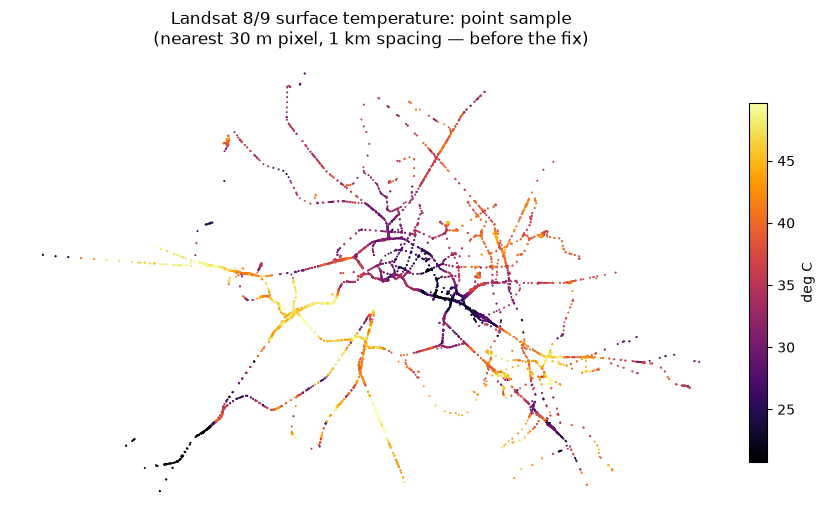

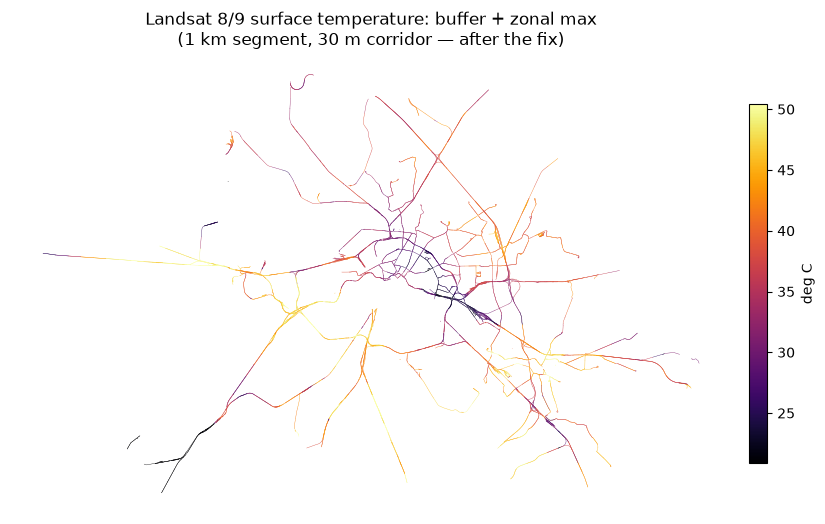

In [13]:
def network_map(column, title, fname, cmap="inferno"):
    vals = samples[column]
    fig, ax = plt.subplots(figsize=(9, 9 / PHI))
    sc = ax.scatter(
        samples.geometry.x, samples.geometry.y, c=vals, s=2, cmap=cmap, linewidths=0,
        vmin=np.nanpercentile(vals, 2), vmax=np.nanpercentile(vals, 98),
    )
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)
    cbar = fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.02)
    cbar.set_label("deg C")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / fname, dpi=200, bbox_inches="tight")
    plt.show()

def corridor_map(segments_gdf, column, title, fname, cmap="inferno"):
    vals = segments_gdf[column]
    vmin, vmax = np.nanpercentile(vals.dropna(), [2, 98])
    fig, ax = plt.subplots(figsize=(9, 9 / PHI))
    segments_gdf.plot(column=column, ax=ax, cmap=cmap, linewidth=0, vmin=vmin, vmax=vmax)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
    cbar = fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.02)
    cbar.set_label("deg C")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / fname, dpi=200, bbox_inches="tight")
    plt.show()

network_map(
    "lst_landsat",
    "Landsat 8/9 surface temperature: point sample\n(nearest 30 m pixel, 1 km spacing — before the fix)",
    "map_lst_landsat_points.png",
)
corridor_map(
    segments, "lst_landsat_zonal_max",
    "Landsat 8/9 surface temperature: buffer + zonal max\n(1 km segment, 30 m corridor — after the fix)",
    "map_lst_landsat_zonal.png",
)

## Export

In [14]:
rail.to_file(RESULTS_DIR / "rail_network.gpkg", driver="GPKG")
samples.to_file(RESULTS_DIR / "rail_lst_points.gpkg", driver="GPKG")
segments.to_file(RESULTS_DIR / "rail_lst_segments.gpkg", driver="GPKG")
summary_df.to_csv(RESULTS_DIR / "summary_stats.csv")
corridors.to_csv(RESULTS_DIR / "top_corridors.csv")
comparison.to_csv(RESULTS_DIR / "temperature_comparison.csv", index=False)
print("Exported: rail_network.gpkg, rail_lst_points.gpkg, rail_lst_segments.gpkg, "
      "summary_stats.csv, top_corridors.csv, temperature_comparison.csv")

Exported: rail_network.gpkg, rail_lst_points.gpkg, rail_lst_segments.gpkg, summary_stats.csv, top_corridors.csv, temperature_comparison.csv


## What would make this genuinely better

- **ECOSTRESS** (~70 m, ISS orbit with varying overpass times including mid-afternoon) would add a
  hotter, more frequent observation than Landsat's fixed ~10:00 overpass. It requires a free NASA
  Earthdata login (AppEEARS), which is the only reason it is not in this notebook.
- **QC masking** (`qa_pixel`) instead of the scene-level `eo:cloud_cover` filter used here.
- **Corridor buffer width** (`CORRIDOR_BUFFER_M`) is a sampling choice, not a survey of the real
  right-of-way; a sensitivity check against a wider or narrower buffer would show how much the result
  depends on it.
- **Ground truth:** DB InfraGO publishes heat-related speed restrictions; crossing them with these
  maps is the natural validation, and the strongest possible figure for the article.
- **Scale-up:** Berlin → Germany is a URL change (`GEOFABRIK_URL`); nothing else in the pipeline
  changes.